# Почему реклама Procrastinate Pro+ не окупается

*Учебный проект Яндекс Практикума · Маркетинговая аналитика*

У развлекательного приложения растут расходы на рекламу. Команда рассчитывает вернуть затраты на привлечение пользователя за две недели. Я проверил, удаётся ли это и какие каналы сильнее всего влияют на результат.

**Данные.** Журнал сессий приложения, покупки пользователей и ежедневные расходы по рекламным каналам. Период наблюдения — с мая по октябрь 2019 года.

### Содержание

1. [Данные и подготовка](#section-1)
2. [Профили и определения метрик](#section-2)
3. [Кто пользуется приложением](#section-3)
4. [Маркетинговые расходы и CAC](#section-4)
5. [Общая окупаемость и поведение](#section-5)
6. [Устройства, страны и рекламные каналы](#section-6)
7. [Причины, рекомендации и ограничения](#section-7)

### Основные результаты

| Вопрос | Результат |
|:--|:--|
| Сколько потрачено на рекламу? | **105 497,30 д.е.** за весь период; **82,65%** бюджета приходится на TipTop и FaceBoom. |
| Окупается ли привлечение за две недели? | Для зрелых платных когорт: CAC **1,116**, LTV14 **0,891**, ROI14 **−20,20%**. |
| Где основная проблема? | TipTop: ROI14 **−46,97%**; FaceBoom: **−26,37%**. Их масштаб определяет общий результат. |
| Что ухудшилось со временем? | С мая по сентябрь общий CAC вырос на **61,4%**, а LTV14 — на **7,1%**. |
| Какая первая мера? | Ограничить масштабирование дорогого TipTop, разобрать слабую повторную монетизацию FaceBoom и тестировать перераспределение бюджета. |

**Денежные единицы (д.е.)** используются потому, что валюта в описании не названа. Под окупаемостью здесь понимается покрытие рекламы выручкой; данных о марже и операционных расходах нет.

<a id="section-1"></a>
## 1. Данные и подготовка

| Таблица | Единица наблюдения | Содержимое |
|:--|:--|:--|
| Визиты | Сессия | Пользователь, страна, устройство, канал, начало и конец сессии. |
| Заказы | Покупка | Пользователь, время покупки и выручка. |
| Расходы | Канал и день | Рекламные расходы данного источника в указанную дату. |

Для повторного расчёта нужны три учебные выгрузки: `visits_info_short.csv`, `orders_info_short.csv` и `costs_info_short.csv`. Ноутбук читает их из своей папки или из `/datasets`.

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy import stats
from IPython.display import display

pd.set_option('display.max_columns', 20)
pd.set_option('display.max_colwidth', 60)
pd.set_option('display.float_format', '{:,.3f}'.format)

COLORS = {
    'ink': '#18324A', 'blue': '#3267A7', 'teal': '#168B89',
    'orange': '#D48235', 'red': '#B94A48', 'gray': '#8898A6',
    'light': '#E5ECF2', 'purple': '#8566A8',
}
mpl.rcParams.update({
    'font.family': 'DejaVu Sans', 'font.size': 10.5,
    'figure.figsize': (11.5, 4.8), 'figure.dpi': 130, 'savefig.dpi': 150,
    'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'text.color': COLORS['ink'], 'axes.labelcolor': COLORS['ink'],
    'axes.titleweight': 'bold', 'axes.titlesize': 13,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#CBD5DF', 'axes.grid': True,
    'grid.color': '#E5ECF2', 'grid.alpha': 0.8,
    'xtick.color': '#52677A', 'ytick.color': '#52677A',
    'axes.axisbelow': True, 'legend.frameon': False,
})

print(f'Python {sys.version.split()[0]} | pandas {pd.__version__} | NumPy {np.__version__}')

Python 3.12.14 | pandas 3.0.1 | NumPy 2.5.5


In [2]:
def table(frame, formats=None, caption=None):
    """Единое оформление таблиц; исходные числа остаются числовыми."""
    styled = (frame.style
              .format(formats or {}, na_rep='—')
              .set_table_styles([
                  {'selector': 'th', 'props': [('background', '#EDF3F8'),
                                               ('color', '#18324A'), ('text-align', 'left')]},
                  {'selector': 'td', 'props': [('padding', '7px 11px'),
                                               ('border-bottom', '1px solid #E5ECF2')]},
                  {'selector': 'caption', 'props': [('caption-side', 'top'),
                                                    ('text-align', 'left'),
                                                    ('font-weight', '600'), ('padding', '8px 0')]},
              ]))
    if caption:
        styled = styled.set_caption(caption)
    display(styled)


def barh(series, ax, title, xlabel, color=None, percent=False):
    """Горизонтальная диаграмма с нулевой базой и подписями значений."""
    series = series.sort_values(ascending=True)
    values = series.to_numpy(dtype=float)
    colors = color if color is not None else COLORS['blue']
    ax.barh(series.index.astype(str), values, color=colors, height=0.68)
    ax.set(title=title, xlabel=xlabel)
    ax.grid(axis='y', visible=False)
    ax.set_xlim(0, max(values) * 1.22 if len(values) and max(values) else 1)
    for i, value in enumerate(values):
        label = f'{value:.1f}%' if percent else f'{value:.2f}'
        ax.text(value + max(values) * 0.018, i, label, va='center', fontsize=9)


def finish(fig):
    fig.tight_layout(pad=1.5)
    plt.show()

In [3]:
FILENAMES = ['visits_info_short.csv', 'orders_info_short.csv', 'costs_info_short.csv']

def find_csv(name):
    candidates = [Path(name), Path('data') / name, Path('/datasets') / name]
    path = next((p for p in candidates if p.is_file()), None)
    if path is None:
        raise FileNotFoundError(f'Не найден {name}; положите его рядом с ноутбуком.')
    return path

raw_visits = pd.read_csv(find_csv(FILENAMES[0]), dtype={'User Id': 'string'})
raw_orders = pd.read_csv(find_csv(FILENAMES[1]), dtype={'User Id': 'string'})
raw_costs = pd.read_csv(find_csv(FILENAMES[2]))
for name, data in [('Визиты', raw_visits), ('Заказы', raw_orders), ('Расходы', raw_costs)]:
    print(f'{name}: {data.shape[0]:,} строк × {data.shape[1]} столбцов')
    print(', '.join(data.columns))

Визиты: 309,901 строк × 6 столбцов
User Id, Region, Device, Channel, Session Start, Session End
Заказы: 40,212 строк × 3 столбцов
User Id, Event Dt, Revenue
Расходы: 1,800 строк × 3 столбцов
dt, Channel, costs


In [4]:
quality = []
for name, data in [('Визиты', raw_visits), ('Заказы', raw_orders), ('Расходы', raw_costs)]:
    quality.append({'Таблица': name, 'Строк': len(data), 'Пропусков': int(data.isna().sum().sum()),
                    'Полных дублей': int(data.duplicated().sum())})
table(pd.DataFrame(quality).set_index('Таблица'), caption='Контроль исходных таблиц')

visits = raw_visits.rename(columns={
    'User Id': 'user_id', 'Region': 'region', 'Device': 'device', 'Channel': 'channel',
    'Session Start': 'session_start', 'Session End': 'session_end',
}).copy()
orders = raw_orders.rename(columns={'User Id': 'user_id', 'Event Dt': 'event_time', 'Revenue': 'revenue'}).copy()
costs = raw_costs.rename(columns={'dt': 'date', 'Channel': 'channel', 'costs': 'cost'}).copy()
for col in ['session_start', 'session_end']:
    visits[col] = pd.to_datetime(visits[col])
orders['event_time'] = pd.to_datetime(orders['event_time'])
costs['date'] = pd.to_datetime(costs['date']).dt.normalize()

assert not costs.duplicated(['date', 'channel']).any()
assert visits['session_end'].ge(visits['session_start']).all()
assert orders['revenue'].ge(0).all() and costs['cost'].ge(0).all()
assert set(orders['user_id']).issubset(set(visits['user_id']))

types = pd.concat([
    visits.dtypes.astype(str).rename('Тип').to_frame().assign(Таблица='Визиты'),
    orders.dtypes.astype(str).rename('Тип').to_frame().assign(Таблица='Заказы'),
    costs.dtypes.astype(str).rename('Тип').to_frame().assign(Таблица='Расходы'),
]).set_index('Таблица', append=True).reorder_levels([1, 0])
table(types, caption='Типы после подготовки')

,Строк,Пропусков,Полных дублей
Таблица,,,
Визиты,309901,0,0
Заказы,40212,0,0
Расходы,1800,0,0


Пропусков и полных дубликатов нет, строки не удаляем. Отрицательных длительностей, выручки или расходов нет; все покупатели найдены в таблице визитов. Ключ «дата — рекламный канал» уникален.

Идентификаторы читаем строками: это ключи, а не числовые показатели. Даты преобразованы в `datetime64`, денежные поля сохранены числовыми. В источнике нет указания часового пояса, поэтому используем его календарную шкалу без выдуманного перевода в UTC.

In [5]:
date_ranges = pd.DataFrame({
    'Начало': [visits['session_start'].min(), orders['event_time'].min(), costs['date'].min()],
    'Конец': [visits['session_start'].max(), orders['event_time'].max(), costs['date'].max()],
}, index=['Начала сессий', 'Покупки', 'Рекламные расходы'])
table(date_ranges, caption='Фактические границы файлов')
print('Самое позднее окончание сессии:', visits['session_end'].max())

,Начало,Конец
Начала сессий,2019-05-01 00:00:41,2019-10-31 23:59:23
Покупки,2019-05-01 00:28:11,2019-10-31 23:56:56
Рекламные расходы,2019-05-01 00:00:00,2019-10-27 00:00:00


Самое позднее окончание сессии: 2019-11-01 01:38:46


Визиты и покупки продолжаются **до 31 октября**, хотя расходы и первые привлечения заканчиваются **27 октября**. Это разные границы: возвращения ранее привлечённых пользователей продолжают наблюдаться. Окончание сессии 1 ноября относится к сессии, начавшейся раньше; активность считаем по началу сессии.

Дата решения — **1 ноября 2019 года**. При проверке зрелости когорт используем фактическую доступность визитов и покупок, а не последнюю дату привлечения.

<a id="section-2"></a>
## 2. Профили и определения метрик

### 2.1. Атрибуция и распределение рекламных расходов

Один профиль соответствует одному пользователю. Канал, страна и устройство берутся **из одной строки первого визита** — first touch. Последующие переходы не меняют источник привлечения и не создают нового пользователя.

Расходы доступны только на уровне **канал × день**. Делим их на число новых пользователей этого канала в этот день и присваиваем полученный CAC каждому профилю. Для страны и устройства суммируем эти пользовательские доли расходов. Это модель распределения общих расходов, а не фактические бюджеты таргетинга по устройству или стране.

`organic` сохраняем в полном наборе профилей, присваивая нулевые **наблюдаемые прямые рекламные расходы**. У платных профилей отсутствие стоимости считается ошибкой сопоставления и не заменяется нулём.

In [6]:
def get_profiles(visits, orders, costs):
    first = (visits.sort_values(['session_start', 'user_id'], kind='stable')
             .drop_duplicates('user_id', keep='first'))
    result = first[['user_id', 'region', 'device', 'channel', 'session_start']].rename(
        columns={'session_start': 'first_touch'}).copy()
    result['first_date'] = result['first_touch'].dt.normalize()
    result['cohort_month'] = result['first_date'].dt.to_period('M').astype(str)
    result['is_payer_any'] = result['user_id'].isin(orders['user_id'])
    result['acquisition_type'] = np.where(result['channel'].eq('organic'), 'Органика', 'Платные')
    new_users = result.groupby(['first_date', 'channel']).size().rename('new_users').reset_index()
    allocation = costs.merge(new_users, left_on=['date', 'channel'],
                             right_on=['first_date', 'channel'], how='left', validate='one_to_one')
    assert allocation['new_users'].notna().all(), 'Есть расходы без новых пользователей.'
    allocation['cac'] = allocation['cost'] / allocation['new_users']
    result = result.merge(allocation[['date', 'channel', 'cac']],
                          left_on=['first_date', 'channel'], right_on=['date', 'channel'],
                          how='left', validate='many_to_one').drop(columns='date')
    paid_mask = result['channel'].ne('organic')
    assert result.loc[paid_mask, 'cac'].notna().all(), 'Есть платные профили без расходов.'
    result.loc[~paid_mask, 'cac'] = 0.0
    assert result['user_id'].is_unique
    assert np.isclose(result['cac'].sum(), costs['cost'].sum())
    return result

profiles = get_profiles(visits, orders, costs)
variability = visits.groupby('user_id')[['region', 'device', 'channel']].nunique().gt(1).sum()
print('Изменение атрибутов между визитами:', variability.to_dict())
print(f'Профилей: {len(profiles):,}; первые визиты: '
      f'{profiles["first_date"].min():%d.%m.%Y} — {profiles["first_date"].max():%d.%m.%Y}.')
print(f'Распределено расходов: {profiles["cac"].sum():,.2f}; в исходнике: {costs["cost"].sum():,.2f}.')
display(profiles.head())

Изменение атрибутов между визитами: {'region': 0, 'device': 5007, 'channel': 5520}
Профилей: 150,008; первые визиты: 01.05.2019 — 27.10.2019.
Распределено расходов: 105,497.30; в исходнике: 105,497.30.


,user_id,region,device,channel,first_touch,first_date,cohort_month,is_payer_any,acquisition_type,cac
0,382394863972,United States,Mac,MediaTornado,2019-05-01 00:00:41,2019-05-01,2019-05,False,Платные,0.240
1,428935481941,UK,PC,AdNonSense,2019-05-01 00:01:35,2019-05-01,2019-05,False,Платные,1.050
2,086266511938,Germany,Android,organic,2019-05-01 00:02:38,2019-05-01,2019-05,False,Органика,0.000
3,763000657462,UK,PC,organic,2019-05-01 00:04:21,2019-05-01,2019-05,False,Органика,0.000
4,791058813280,France,Android,LeapBob,2019-05-01 00:05:17,2019-05-01,2019-05,False,Платные,0.210


Получено **150 008 профилей**: 93 569 из платных каналов и 56 439 organic. Период первых привлечений — **1 мая–27 октября**. Все 105 497,30 д.е. рекламных расходов распределены без остатка.

У **5 520 пользователей** менялся канал визита, у **5 007** — устройство. Поэтому группировка заказов по последнему визиту или подсчёт пользователей отдельно в каждом канале приводили бы к другой атрибуции и повторному учёту. В этой работе правило первого касания применяется последовательно.

### 2.2. Единый горизонт и зрелость когорт

Основной расчёт использует **14 календарных дней: возраста 0–13**, где день 0 — дата первого визита. Например, для привлечения 18 октября доступны даты 18–31 октября. Нулевой день может быть короче 24 часов; это когортная календарная трактовка двух недель. В конце проверим чувствительность общего результата к точным 14 × 24 часам.

В основной анализ LTV, CAC, ROI, конверсии и удержания входят одни и те же зрелые профили — привлечённые **не позднее 18 октября**. Молодые когорты не получают вымышленную нулевую выручку за ещё не наступившие дни. Октябрьские точки динамики относятся только к **1–18 октября**.

| Метрика | Определение |
|:--|:--|
| CAC | Расходы на привлечение / все привлечённые пользователи выбранной когорты. |
| LTV14 | Суммарная выручка за дни 0–13 / все пользователи когорты, включая неплательщиков. Это выручка за ограниченный горизонт, не пожизненная ценность. |
| ROI14 | `(выручка14 − расходы) / расходы = LTV14 / CAC − 1`; порог окупаемости — **0%**. |
| Конверсия14 | Доля пользователей с хотя бы одной покупкой в дни 0–13. |
| Retention D7 / D13 | Доля пользователей с визитом ровно на 7-й / 13-й календарный день после привлечения. Это не накопительное удержание. |

LTV и конверсия по дням накапливаются. Retention считается для отдельного дня; день 0 равен 100% по определению профиля. Итоги и месячные точки рассчитываем отношением сумм, а не средним дневных ROI.

In [7]:
AS_OF = pd.Timestamp('2019-11-01')
HORIZON = 14
data_end = min(visits['session_start'].max().normalize() + pd.Timedelta(days=1),
               orders['event_time'].max().normalize() + pd.Timedelta(days=1), AS_OF)
profiles['mature14'] = profiles['first_date'] + pd.Timedelta(days=HORIZON) <= data_end

order_facts = orders.merge(profiles[['user_id', 'first_touch', 'first_date']],
                           on='user_id', how='left', validate='many_to_one')
order_facts['age'] = (order_facts['event_time'].dt.normalize() - order_facts['first_date']).dt.days
assert order_facts['event_time'].ge(order_facts['first_touch']).all()
within14 = order_facts.loc[order_facts['age'].between(0, HORIZON - 1)]
revenue14 = within14.groupby('user_id')['revenue'].sum()
orders14 = within14.groupby('user_id').size()
first_purchase = order_facts.groupby('user_id')['age'].min()
profiles['revenue14'] = profiles['user_id'].map(revenue14).fillna(0)
profiles['orders14'] = profiles['user_id'].map(orders14).fillna(0).astype(int)
profiles['first_purchase_age'] = profiles['user_id'].map(first_purchase)
profiles['payer14'] = profiles['first_purchase_age'].between(0, HORIZON - 1)

visit_facts = visits[['user_id', 'session_start']].merge(profiles[['user_id', 'first_date']],
                                                       on='user_id', validate='many_to_one')
visit_facts['age'] = (visit_facts['session_start'].dt.normalize() - visit_facts['first_date']).dt.days
visit_facts = visit_facts[['user_id', 'age']].drop_duplicates()
assert visit_facts['age'].ge(0).all()
for age in [1, 7, 13]:
    profiles[f'ret_d{age}'] = profiles['user_id'].isin(visit_facts.loc[visit_facts['age'].eq(age), 'user_id'])

mature = profiles.loc[profiles['mature14']].copy()
paid = mature.loc[mature['channel'].ne('organic')].copy()
organic = mature.loc[mature['channel'].eq('organic')].copy()
paid['portfolio'] = 'Платное привлечение'

scope = pd.DataFrame({
    'Пользователей': [len(profiles), len(mature), len(paid), len(organic)],
    'Распределённые расходы': [profiles['cac'].sum(), mature['cac'].sum(), paid['cac'].sum(), 0],
}, index=['Все профили', 'Зрелые: 14 календарных дней', 'Зрелые платные', 'Зрелая органика'])
table(scope, {'Пользователей': '{:,.0f}', 'Распределённые расходы': '{:,.2f}'},
      'Границы сравнимой выборки')
print('Последняя зрелая дата привлечения:', mature['first_date'].max().date())

,Пользователей,Распределённые расходы
Все профили,"150,008","105,497.30"
Зрелые: 14 календарных дней,"141,709","98,298.93"
Зрелые платные,"88,056","98,298.93"
Зрелая органика,"53,653",0.00


Последняя зрелая дата привлечения: 2019-10-18


Основная платная выборка — **88 056 пользователей** с распределёнными расходами **98 298,94 д.е.** Остальные 7 198,37 д.е. относятся к ещё не созревшим платным когортам; они остаются в общем анализе бюджета, но не сравниваются с полной 14-дневной выручкой.

Органика нужна для портрета аудитории и отдельного поведенческого ориентира. В показатель окупаемости **платного** привлечения её выручку не добавляем: иначе бюджет рекламы выглядел бы эффективнее за счёт другого источника.

In [8]:
def summarize(base, dimensions):
    dims = [dimensions] if isinstance(dimensions, str) else list(dimensions)
    result = base.groupby(dims, observed=True).agg(
        users=('user_id', 'size'), payers14=('payer14', 'sum'),
        spend=('cac', 'sum'), revenue14=('revenue14', 'sum'),
        orders14=('orders14', 'sum'), conversion14=('payer14', 'mean'),
        retention7=('ret_d7', 'mean'), retention13=('ret_d13', 'mean'))
    result['CAC'] = result['spend'] / result['users']
    result['LTV14'] = result['revenue14'] / result['users']
    result['ROI14'] = result['revenue14'].div(result['spend'].replace(0, np.nan)) - 1
    result['gap14'] = result['revenue14'] - result['spend']
    result['ARPPU14'] = result['revenue14'] / result['payers14'].replace(0, np.nan)
    result['orders_per_payer14'] = result['orders14'] / result['payers14'].replace(0, np.nan)
    return result

def get_curves(base, dimension):
    sizes = base.groupby(dimension, observed=True).size()
    attrs = base[['user_id', dimension]]
    revenue = within14[['user_id', 'age', 'revenue']].merge(attrs, on='user_id', validate='many_to_one')
    revenue_age = (revenue.groupby([dimension, 'age'], observed=True)['revenue'].sum()
                   .unstack('age').reindex(index=sizes.index, columns=range(HORIZON)).fillna(0))
    ltv = revenue_age.cumsum(axis=1).div(sizes, axis=0)
    purchases = base.loc[base['payer14']].groupby([dimension, 'first_purchase_age'], observed=True).size()
    conversion = (purchases.unstack().reindex(index=sizes.index, columns=range(HORIZON)).fillna(0)
                  .cumsum(axis=1).div(sizes, axis=0))
    sessions = visit_facts.loc[visit_facts['age'].between(0, HORIZON - 1)].merge(
        attrs, on='user_id', validate='many_to_one')
    retention = (sessions.groupby([dimension, 'age'], observed=True)['user_id'].nunique().unstack()
                 .reindex(index=sizes.index, columns=range(HORIZON)).fillna(0).div(sizes, axis=0))
    assert np.allclose(retention[0], 1)
    assert (ltv.diff(axis=1).iloc[:, 1:] >= -1e-10).all().all()
    assert (conversion.diff(axis=1).iloc[:, 1:] >= -1e-10).all().all()
    return ltv, conversion, retention

def summary_table(base, dimension, caption):
    result = summarize(base, dimension).sort_values('spend', ascending=False)
    view = result[['users', 'CAC', 'LTV14', 'ROI14', 'conversion14', 'retention7']].rename(columns={
        'users': 'Пользователей', 'ROI14': 'ROI14', 'conversion14': 'Конверсия14', 'retention7': 'Retention D7'})
    table(view, {'Пользователей': '{:,.0f}', 'CAC': '{:.3f}', 'LTV14': '{:.3f}',
                 'ROI14': '{:+.1%}', 'Конверсия14': '{:.1%}', 'Retention D7': '{:.1%}'}, caption)
    return result

total = summarize(paid, 'portfolio').iloc[0]
channel_metrics = summarize(paid, 'channel')
assert np.isclose(channel_metrics['spend'].sum(), total['spend'])
assert np.isclose(channel_metrics['revenue14'].sum(), total['revenue14'])

<a id="section-3"></a>
## 3. Кто пользуется приложением

Портрет строим по **всем 150 008 профилям**, включая organic. Плательщик здесь — пользователь с любой покупкой за доступную историю. У поздних привлечений меньше времени на покупку, поэтому эти описательные доли не заменяют сопоставимую конверсию14 зрелых когорт.

In [9]:
def audience_table(dimension):
    result = profiles.groupby(dimension).agg(users=('user_id', 'size'), payers=('is_payer_any', 'sum'))
    result['payer_share'] = result['payers'] / result['users']
    result = result.sort_values('payers', ascending=False)
    table(result.rename(columns={'users': 'Пользователей', 'payers': 'Плательщиков',
                                  'payer_share': 'Доля плательщиков'}),
          {'Пользователей': '{:,.0f}', 'Плательщиков': '{:,.0f}', 'Доля плательщиков': '{:.2%}'})

audience_table('region')

,Пользователей,Плательщиков,Доля плательщиков
region,,,
United States,"100,002","6,902",6.90%
UK,"17,575",700,3.98%
France,"17,450",663,3.80%
Germany,"14,981",616,4.11%


**США** — крупнейший рынок: **100 002 пользователя**, из них **6 902 плательщика (6,90%)**. В UK, France и Germany по 15–18 тысяч пользователей и около 3,8–4,1% плательщиков. Масштаб и высокая доля платящих ещё не означают хорошую окупаемость: ниже сопоставим выручку со стоимостью привлечения.

In [10]:
audience_table('device')

,Пользователей,Плательщиков,Доля плательщиков
device,,,
iPhone,"54,479","3,382",6.21%
Android,"35,032","2,050",5.85%
Mac,"30,042","1,912",6.36%
PC,"30,455","1,537",5.05%


Больше всего пользователей и плательщиков у **iPhone**: 54 479 и 3 382 соответственно. Наибольшая доля плательщиков у **Mac — 6,36%**, у iPhone — 6,21%, Android — 5,85%, PC — 5,05%. Это атрибут устройства первого визита; последующие покупки относятся к тому же профилю даже при смене устройства.

In [11]:
audience_table('channel')

,Пользователей,Плательщиков,Доля плательщиков
channel,,,
FaceBoom,"29,144","3,557",12.20%
TipTop,"19,561","1,878",9.60%
organic,"56,439","1,160",2.06%
WahooNetBanner,"8,553",453,5.30%
AdNonSense,"3,880",440,11.34%
RocketSuperAds,"4,448",352,7.91%
LeapBob,"8,553",262,3.06%
OppleCreativeMedia,"8,605",233,2.71%
lambdaMediaAds,"2,149",225,10.47%


**FaceBoom** приводит больше всего плательщиков — **3 557**, далее **TipTop — 1 878**. Органика — крупнейший источник по общей аудитории (56 439), но её доля плательщиков ниже — 2,06%. FaceBoom, AdNonSense и lambdaMediaAds выделяются высокой долей платящих. Низкая конверсия может сочетаться с окупаемостью при дешёвом привлечении; высокая — с убытком на рекламных расходах при слабой повторной монетизации.

<a id="section-4"></a>
## 4. Маркетинговые расходы и CAC

### 4.1. Общий бюджет и стоимость нового пользователя

Здесь используем **весь период расходов и все новые профили**, без требования 14-дневной зрелости. CAC считается на привлечённого пользователя, а не на покупателя. Расходов на organic в файле нет.

,"Расходы, д.е.",Новых пользователей,Доля бюджета,"CAC, д.е."
channel,,,,
TipTop,"54,751.30","19,561",51.9%,2.799
FaceBoom,"32,445.60","29,144",30.8%,1.113
WahooNetBanner,"5,151.00","8,553",4.9%,0.602
AdNonSense,"3,911.25","3,880",3.7%,1.008
OppleCreativeMedia,"2,151.25","8,605",2.0%,0.250
RocketSuperAds,"1,833.00","4,448",1.7%,0.412
LeapBob,"1,797.60","8,553",1.7%,0.210
lambdaMediaAds,"1,557.60","2,149",1.5%,0.725
MediaTornado,954.48,"4,364",0.9%,0.219


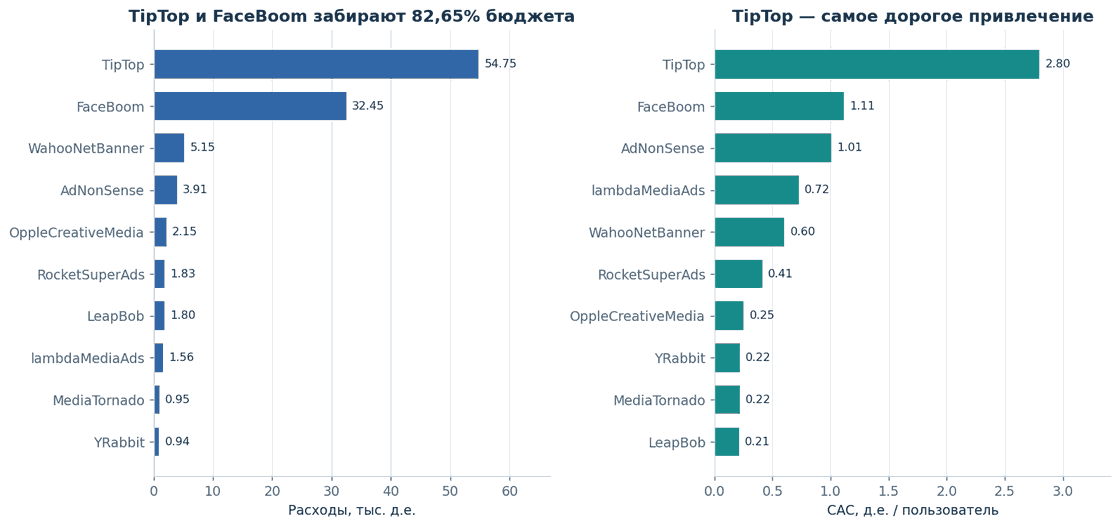

In [12]:
budget = costs.groupby('channel')['cost'].sum().sort_values(ascending=False)
all_new = profiles.loc[profiles['channel'].ne('organic')].groupby('channel').size()
budget_report = pd.DataFrame({'Расходы, д.е.': budget, 'Новых пользователей': all_new}).loc[budget.index]
budget_report['Доля бюджета'] = budget_report['Расходы, д.е.'] / budget.sum()
budget_report['CAC, д.е.'] = budget_report['Расходы, д.е.'] / budget_report['Новых пользователей']
table(budget_report, {'Расходы, д.е.': '{:,.2f}', 'Новых пользователей': '{:,.0f}',
                       'Доля бюджета': '{:.1%}', 'CAC, д.е.': '{:.3f}'},
      f'Весь бюджет: {budget.sum():,.2f} д.е.')
fig, axes = plt.subplots(1, 2, figsize=(12.5, 6))
barh(budget / 1000, axes[0], 'TipTop и FaceBoom забирают 82,65% бюджета', 'Расходы, тыс. д.е.')
barh(budget_report['CAC, д.е.'], axes[1], 'TipTop — самое дорогое привлечение',
     'CAC, д.е. / пользователь', color=COLORS['teal'])
finish(fig)

Общий бюджет — **105 497,30 д.е.** На TipTop потрачено **54 751,30**, на FaceBoom — **32 445,60**; вместе это **82,65%** всех расходов. Изменение эффективности этих двух каналов сильнее всего влияет на портфель.

CAC выше всего у TipTop — около **2,80 д.е.**, далее FaceBoom — **1,11**, AdNonSense — **1,01**. Самые дешёвые каналы не обязательно лучшие: для решения нужна не одна стоимость привлечения, а её соотношение с выручкой и качеством пользователей.

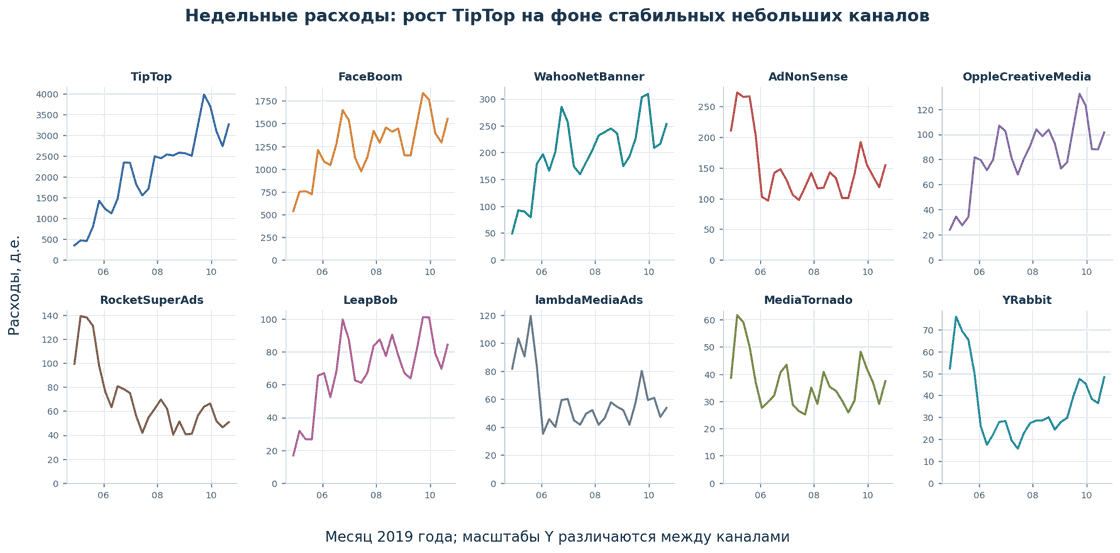

In [13]:
CHANNEL_ORDER = budget.index.tolist()
channel_palette = ['#3267A7', '#D48235', '#168B89', '#B94A48', '#8566A8',
                   '#7C594B', '#AD5E92', '#687E8E', '#718641', '#1B8FA8']
CHANNEL_COLORS = dict(zip(CHANNEL_ORDER, channel_palette))
DIMENSION_ORDERS = {'channel': CHANNEL_ORDER,
                    'device': ['iPhone', 'Mac', 'Android', 'PC'],
                    'region': ['United States', 'UK', 'France', 'Germany']}

def spend_facets(period, title):
    data = costs.copy()
    data['period'] = data['date'].dt.to_period(period).dt.start_time
    grouped = data.groupby(['channel', 'period'])['cost'].sum()
    fig, axes = plt.subplots(2, 5, figsize=(14, 6.5))
    for ax, channel in zip(axes.flat, CHANNEL_ORDER):
        series = grouped.loc[channel]
        if period == 'M':
            ax.bar(series.index, series, width=20, color=CHANNEL_COLORS[channel])
        else:
            ax.plot(series.index, series, color=CHANNEL_COLORS[channel], linewidth=1.8)
        ax.set_title(channel, fontsize=10)
        ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2 if period != 'M' else 1))
        ax.xaxis.set_major_formatter(mdates.DateFormatter('%m'))
        ax.tick_params(axis='both', labelsize=8)
        ax.set_ylim(bottom=0)
    fig.suptitle(title, fontsize=15, fontweight='bold', y=1.02)
    fig.supxlabel('Месяц 2019 года; масштабы Y различаются между каналами')
    fig.supylabel('Расходы, д.е.')
    finish(fig)

spend_facets('W-SUN', 'Недельные расходы: рост TipTop на фоне стабильных небольших каналов')

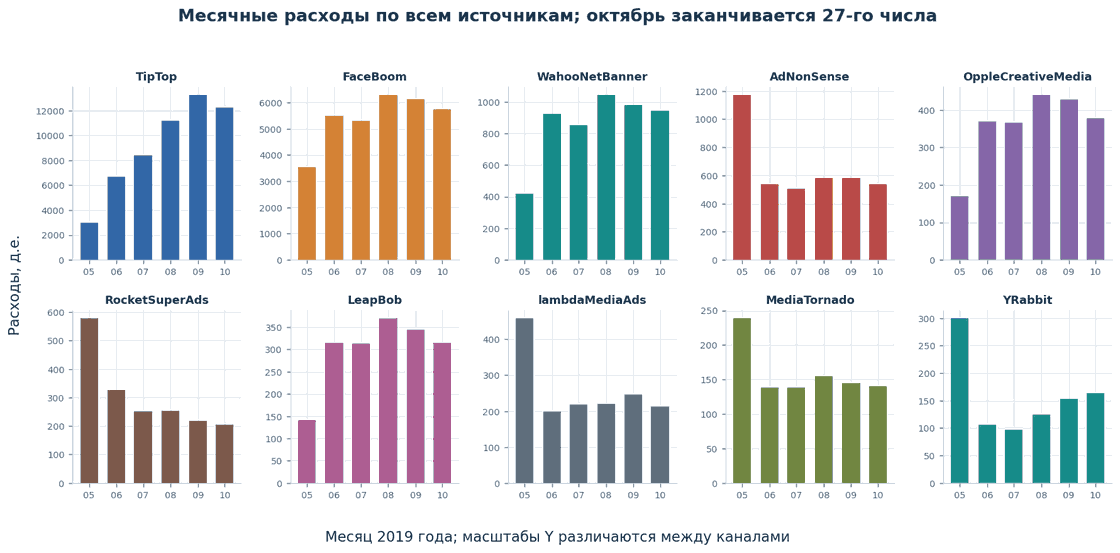

month,2019-05,2019-06,2019-07,2019-08,2019-09,2019-10
channel,,,,,,
TipTop,"2,981.00","6,675.60","8,410.20","11,202.00","13,232.50","12,250.00"
FaceBoom,"3,524.40","5,501.10","5,294.30","6,274.40","6,114.90","5,736.50"
WahooNetBanner,418.80,921.00,851.40,"1,040.40",977.40,942.00
AdNonSense,"1,169.70",538.65,504.00,579.60,581.70,537.60
OppleCreativeMedia,169.75,370.00,366.50,439.25,427.75,378.00
RocketSuperAds,577.98,325.72,252.07,253.11,218.40,205.72
LeapBob,140.28,314.58,313.53,369.81,343.98,315.42
lambdaMediaAds,458.40,199.20,219.20,220.00,247.20,213.60
MediaTornado,238.56,138.00,138.48,154.56,144.72,140.16


In [14]:
spend_facets('M', 'Месячные расходы по всем источникам; октябрь заканчивается 27-го числа')
monthly_cost = costs.assign(month=costs['date'].dt.to_period('M').astype(str)).pivot_table(
    index='channel', columns='month', values='cost', aggfunc='sum').reindex(CHANNEL_ORDER)
table(monthly_cost, {col: '{:,.2f}' for col in monthly_cost.columns},
      'Расходы по месяцам, д.е.; октябрь — неполный календарный месяц')

Неделя начинается в понедельник; расходы сгруппированы по календарным неделям, первая из которых частичная. Месячный и недельный графики показывают каждый канал отдельно, поэтому небольшой бюджет не скрывается за TipTop.

Расходы **TipTop** выросли с **2 981,00 в мае до 13 232,50 д.е. в сентябре**. FaceBoom также получил больше бюджета, чем в начале периода, а небольшие источники в основном оставались на гораздо меньшем масштабе. Октябрь нельзя напрямую сравнивать с полным сентябрём по сумме: расходы доступны только до 27 октября. Рост бюджета сам по себе не объясняет проблему — далее проверим, успела ли вырасти ценность привлечённых пользователей.

<a id="section-5"></a>
## 5. Общая окупаемость и поведение

### 5.1. Окупается ли платное привлечение за 14 дней?

Все графики этого и следующего раздела используют только **зрелые когорты**. LTV и CAC относятся к одним и тем же пользователям. Порог ROI — 0%, поскольку из отношения LTV/CAC вычтена единица.

,Пользователей,CAC,LTV14,ROI14,Конверсия14,Retention D7
portfolio,,,,,,
Платное привлечение,"88,056",1.116,0.891,-20.2%,8.0%,2.9%


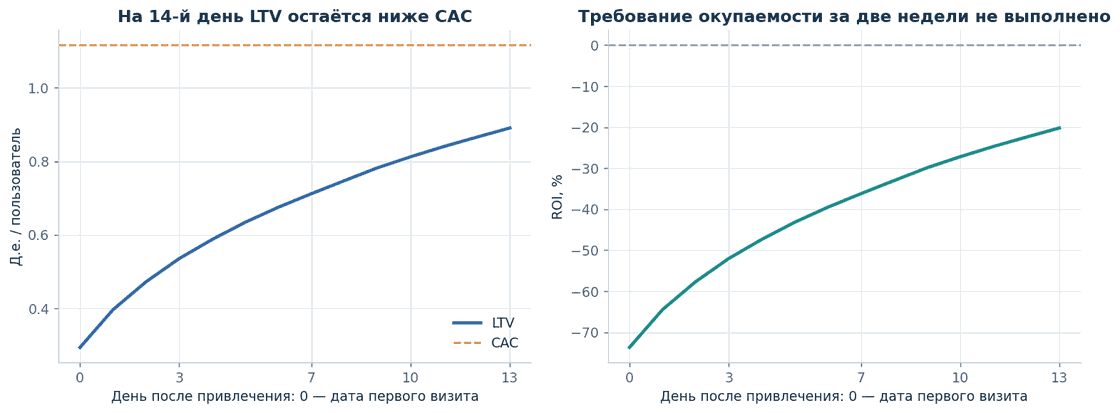

Выручка14: 78,442.56; расходы: 98,298.93; разность: -19,856.38 д.е.


In [15]:
overall = summary_table(paid, 'portfolio', '88 056 платных пользователей с доступными днями 0–13')
overall_ltv, overall_conversion, overall_retention = get_curves(paid, 'portfolio')
ages = np.arange(HORIZON)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.7))
axes[0].plot(ages, overall_ltv.iloc[0], color=COLORS['blue'], linewidth=2.5, label='LTV')
axes[0].axhline(total['CAC'], color=COLORS['orange'], linestyle='--', label='CAC')
axes[0].set(title='На 14-й день LTV остаётся ниже CAC', ylabel='Д.е. / пользователь')
axes[0].legend()
roi_curve = overall_ltv.iloc[0] / total['CAC'] - 1
axes[1].plot(ages, roi_curve * 100, color=COLORS['teal'], linewidth=2.5)
axes[1].axhline(0, color=COLORS['gray'], linestyle='--')
axes[1].set(title='Требование окупаемости за две недели не выполнено', ylabel='ROI, %')
for ax in axes:
    ax.set_xlabel('День после привлечения: 0 — дата первого визита')
    ax.set_xticks([0, 3, 7, 10, 13])
finish(fig)
print(f'Выручка14: {total["revenue14"]:,.2f}; расходы: {total["spend"]:,.2f}; '
      f'разность: {total["gap14"]:,.2f} д.е.')

За первые 14 календарных дней пользователи приносят **78 442,56 д.е.** при расходах **98 298,94 д.е.** LTV14 — **0,891**, CAC — **1,116**, ROI14 — **−20,20%**. На этом горизонте не покрыто **19 856,38 д.е.** расходов на привлечение.

Вывод относится к возврату рекламных расходов выручкой за две недели. Он не означает, что пользователь никогда не окупится позже, и не является расчётом чистого финансового убытка приложения.

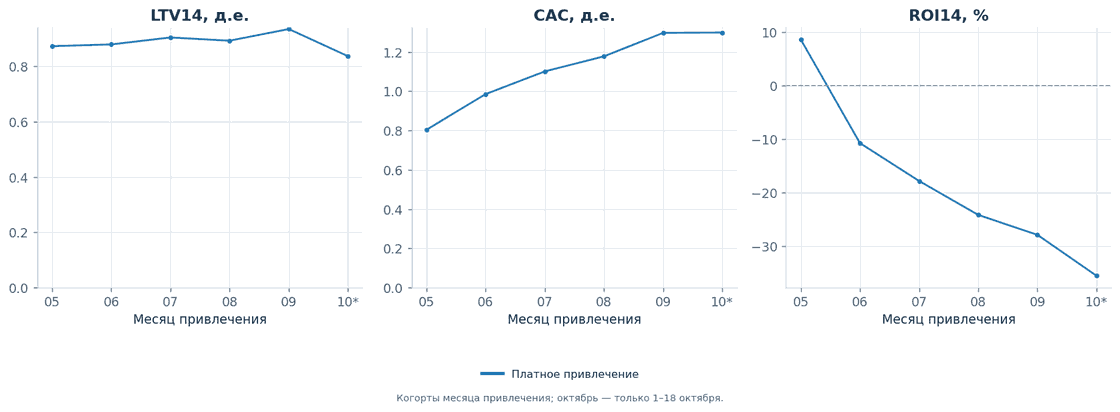

,Пользователей,CAC,LTV14,ROI14,Конверсия14,Retention D7
cohort_month,,,,,,
2019-05,"12,416",0.804,0.873,+8.6%,7.76%,2.84%
2019-06,"15,315",0.985,0.879,-10.8%,8.00%,2.84%
2019-07,"14,941",1.101,0.904,-17.9%,7.98%,2.76%
2019-08,"17,545",1.177,0.892,-24.2%,7.95%,2.88%
2019-09,"17,303",1.297,0.935,-27.9%,8.30%,2.96%
2019-10,"10,536",1.299,0.836,-35.6%,7.92%,2.78%


In [16]:
def palette_for(dimension, labels):
    if dimension == 'channel':
        return {label: CHANNEL_COLORS[label] for label in labels}
    if dimension == 'acquisition_type':
        return {'Платные': COLORS['blue'], 'Органика': COLORS['gray']}
    return {label: mpl.colormaps['tab10'](i) for i, label in enumerate(labels)}

def ordered_labels(base, dimension):
    labels = base[dimension].drop_duplicates().tolist()
    return [x for x in DIMENSION_ORDERS.get(dimension, sorted(labels)) if x in labels]

def finish_with_legend(fig, axes, labels, colors, footer=True):
    handles = [mpl.lines.Line2D([0], [0], color=colors[label], linewidth=2.5) for label in labels]
    rows = int(np.ceil(len(labels) / 4))
    fig.legend(handles, labels, ncol=min(4, len(labels)), loc='lower center',
               bbox_to_anchor=(0.5, 0.035 if footer else 0), fontsize=9)
    if footer:
        fig.text(0.5, 0.005, 'Когорты месяца привлечения; октябрь — только 1–18 октября.',
                 ha='center', fontsize=8, color='#52677A')
    fig.tight_layout(rect=[0, 0.13 + rows * 0.025, 1, 1])
    plt.show()

def plot_monthly(base, dimension=None, behavior=False):
    data = base.copy()
    if dimension is None:
        dimension = 'portfolio'
        data[dimension] = 'Платное привлечение'
    labels = ordered_labels(data, dimension)
    colors = palette_for(dimension, labels)
    monthly = summarize(data, ['cohort_month', dimension])
    months = sorted(data['cohort_month'].unique())
    metrics = [('conversion14', 'Конверсия14, %', 100), ('retention7', 'Retention D7, %', 100)] if behavior else [
        ('LTV14', 'LTV14, д.е.', 1), ('CAC', 'CAC, д.е.', 1), ('ROI14', 'ROI14, %', 100)]
    fig, axes = plt.subplots(1, len(metrics), figsize=(13, 5 if len(labels) > 4 else 4.7))
    for ax, (metric, title, scale) in zip(axes, metrics):
        for label in labels:
            series = monthly.xs(label, level=dimension)[metric].reindex(months)
            ax.plot(range(len(months)), series.to_numpy() * scale, color=colors[label], marker='o', markersize=3)
        ax.set(title=title, xlabel='Месяц привлечения', xticks=range(len(months)),
               xticklabels=[m[5:] + ('*' if m.endswith('10') else '') for m in months])
        if metric == 'ROI14':
            ax.axhline(0, color=COLORS['gray'], linestyle='--', linewidth=1)
        else:
            ax.set_ylim(bottom=0)
    finish_with_legend(fig, axes, labels, colors)

plot_monthly(paid)
monthly_paid = summarize(paid, 'cohort_month')
table(monthly_paid[['users', 'CAC', 'LTV14', 'ROI14', 'conversion14', 'retention7']]
      .rename(columns={'users': 'Пользователей', 'conversion14': 'Конверсия14', 'retention7': 'Retention D7'}),
      {'Пользователей': '{:,.0f}', 'CAC': '{:.3f}', 'LTV14': '{:.3f}', 'ROI14': '{:+.1%}',
       'Конверсия14': '{:.2%}', 'Retention D7': '{:.2%}'}, 'Сопоставимые 14-дневные метрики месячных когорт')

С мая по сентябрь **CAC вырос с 0,804 до 1,297 д.е. (+61,4%)**, тогда как LTV14 — с 0,873 до 0,935 (+7,1%). ROI14 ухудшился с **+8,57% до −27,94%**. Основное расхождение связано с ростом стоимости привлечения, который не компенсируется ростом ранней выручки.

Октябрьские зрелые когорты также не окупаются за две недели, но эта точка описывает только первые 18 дней месяца. Суммы расходов из предыдущего раздела имеют более широкую календарную границу и не подставляются сюда вместо расходов зрелых когорт.

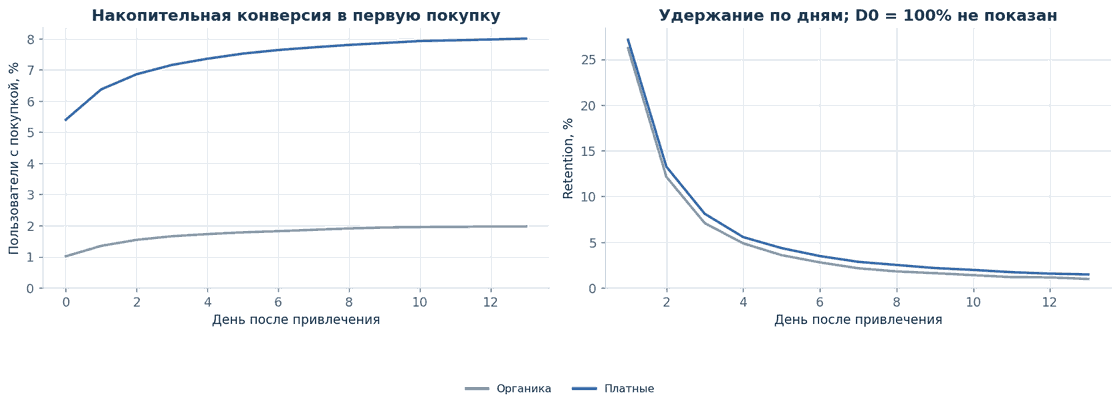

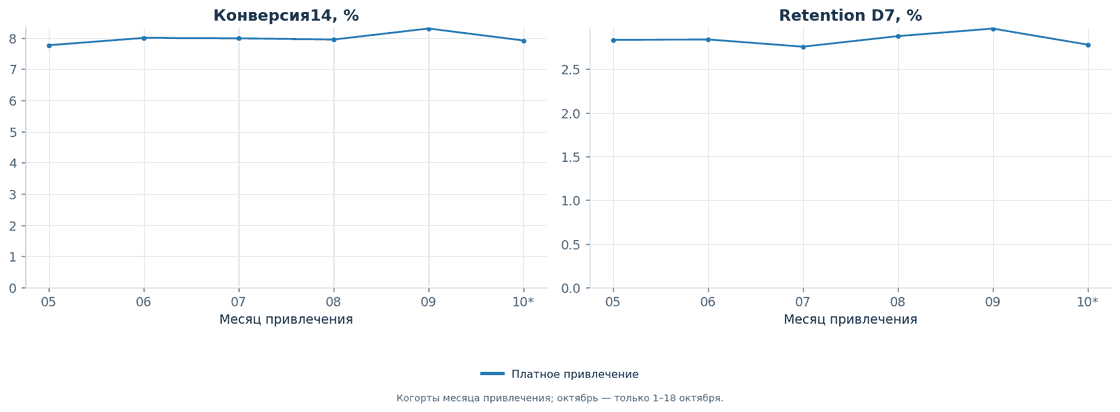

In [17]:
def plot_behavior_curves(base, dimension):
    labels = ordered_labels(base, dimension)
    colors = palette_for(dimension, labels)
    _, conversion, retention = get_curves(base, dimension)
    fig, axes = plt.subplots(1, 2, figsize=(13, 5 if len(labels) > 4 else 4.7))
    for label in labels:
        axes[0].plot(ages, conversion.loc[label] * 100, color=colors[label], linewidth=2)
        axes[1].plot(ages[1:], retention.loc[label].iloc[1:] * 100, color=colors[label], linewidth=2)
    axes[0].set(title='Накопительная конверсия в первую покупку', ylabel='Пользователи с покупкой, %')
    axes[1].set(title='Удержание по дням; D0 = 100% не показан', ylabel='Retention, %')
    for ax in axes:
        ax.set_xlabel('День после привлечения')
        ax.set_ylim(bottom=0)
    finish_with_legend(fig, axes, labels, colors, footer=False)

plot_behavior_curves(mature, 'acquisition_type')
plot_monthly(paid, behavior=True)

Конверсия14 платного привлечения — **8,00%**; месячные значения находятся около 7,8–8,3%. Такая относительная стабильность не компенсирует заметно выросший CAC.

Органика имеет другую конверсию и структуру аудитории, поэтому её используем как описательный ориентир. У органики нет распределённых прямых рекламных расходов, но это не доказывает нулевую полную стоимость её получения. ROI для неё при нулевом знаменателе не рассчитываем.

<a id="section-6"></a>
## 6. Устройства, страны и рекламные каналы

Для каждого разреза сравниваем LTV и ROI по дням, месячную динамику LTV/CAC/ROI, конверсию и удержание по возрастам, а также их месячную динамику. Все показатели относятся к **одним зрелым платным профилям**. Цвет категории одинаков в графиках своего разреза; небольшой размер отдельных групп учитываем при рекомендациях.

In [18]:
def plot_economics_curves(base, dimension):
    labels = ordered_labels(base, dimension)
    colors = palette_for(dimension, labels)
    ltv, _, _ = get_curves(base, dimension)
    summary = summarize(base, dimension)
    fig, axes = plt.subplots(1, 2, figsize=(13, 5 if len(labels) > 4 else 4.7))
    for label in labels:
        axes[0].plot(ages, ltv.loc[label], color=colors[label], linewidth=2)
        axes[1].plot(ages, (ltv.loc[label] / summary.loc[label, 'CAC'] - 1) * 100,
                     color=colors[label], linewidth=2)
    axes[0].set(title='Накопительная выручка на привлечённого', ylabel='LTV, д.е. / пользователь')
    axes[1].set(title='Покрытие рекламных расходов выручкой', ylabel='ROI, %')
    axes[1].axhline(0, color=COLORS['gray'], linestyle='--', linewidth=1)
    for ax in axes:
        ax.set_xlabel('День после привлечения')
        ax.set_xticks([0, 3, 7, 10, 13])
    finish_with_legend(fig, axes, labels, colors, footer=False)

### 6.1. Устройства

,Пользователей,CAC,LTV14,ROI14,Конверсия14,Retention D7
device,,,,,,
iPhone,"31,848",1.275,0.906,-29.0%,8.5%,2.8%
Mac,"17,656",1.275,0.920,-27.8%,8.7%,2.7%
Android,"20,546",1.018,0.897,-11.9%,8.0%,2.8%
PC,"18,006",0.792,0.829,+4.6%,6.5%,3.0%


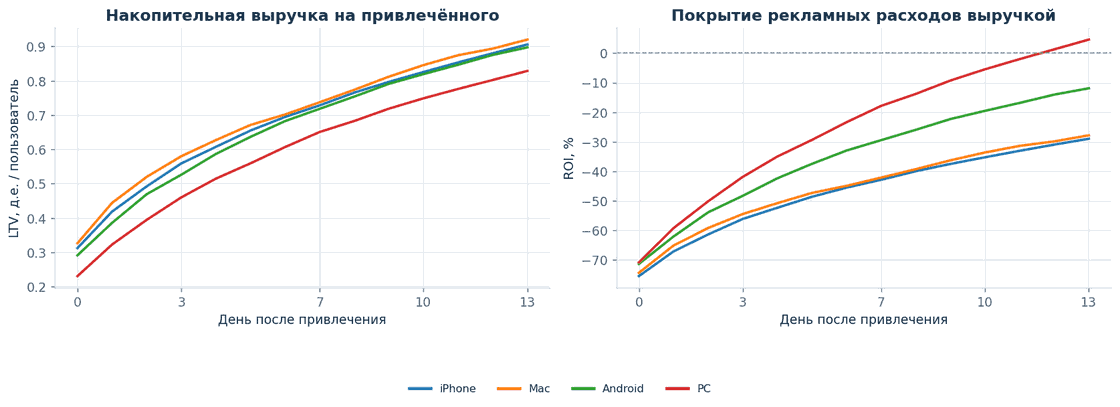

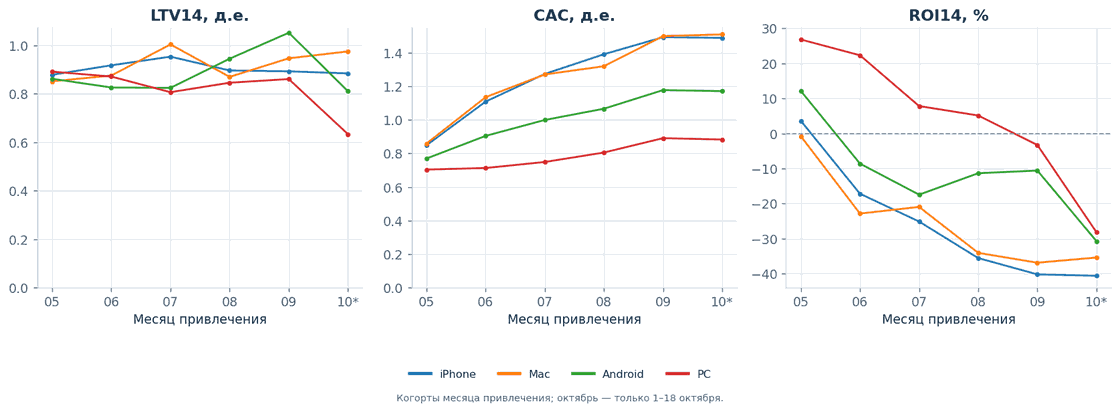

In [19]:
device_metrics = summary_table(paid, 'device', 'Устройство первого визита; расходы распределены через канал и день')
plot_economics_curves(paid, 'device')
plot_monthly(paid, 'device')

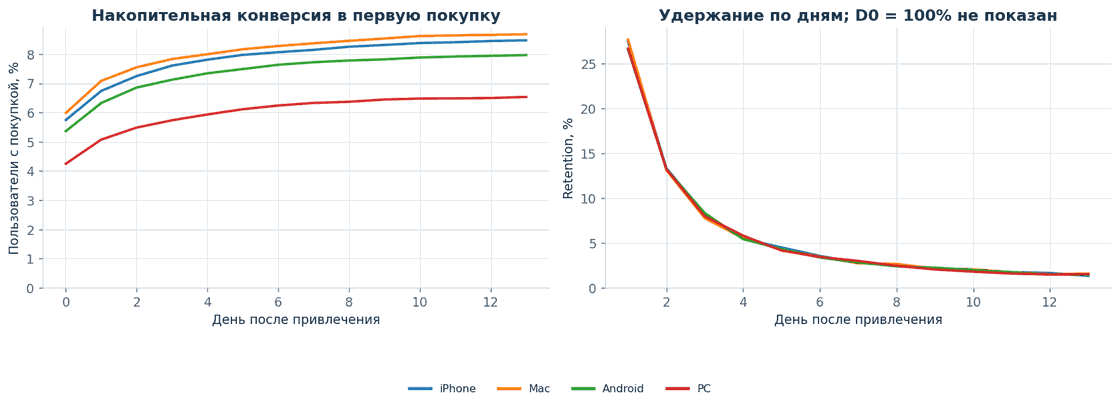

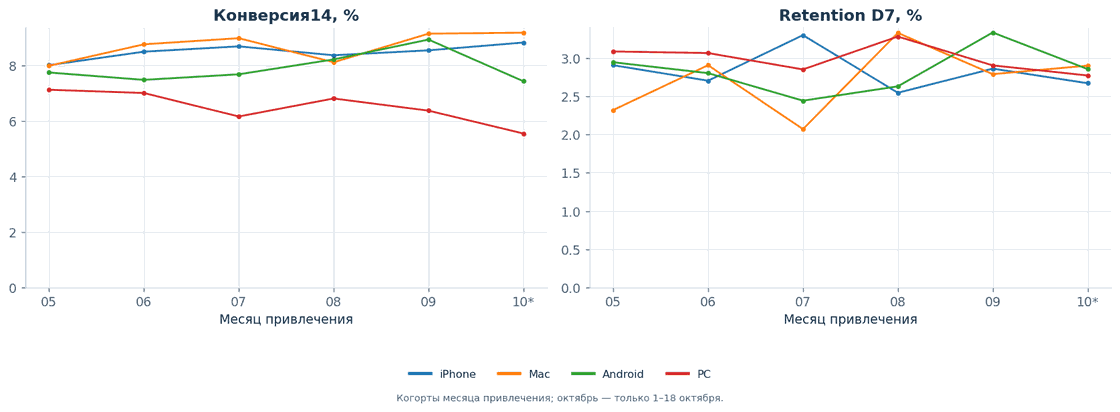

In [20]:
plot_behavior_curves(paid, 'device')
plot_monthly(paid, 'device', behavior=True)

По 14-дневному ROI **iPhone (−28,98%)** и **Mac (−27,82%)** показывают наиболее слабые результаты; **Android — −11,88%**, **PC — +4,62%**. При этом у Mac и iPhone выше конверсия, чем у PC, и сопоставимая либо большая ранняя выручка на пользователя. Недостаточная окупаемость связана прежде всего с более высоким распределённым CAC.

Из этих агрегатов нельзя заключить, что проблема технически вызвана iOS или macOS. Устройства получают разную смесь рекламных каналов; далее проверим этот состав. Положительный средний результат PC также не означает, что каждый канал на PC эффективен.

### 6.2. Страны

,Пользователей,CAC,LTV14,ROI14,Конверсия14,Retention D7
region,,,,,,
United States,"58,166",1.454,0.989,-32.0%,9.6%,2.8%
France,"10,454",0.460,0.662,+43.9%,4.8%,2.8%
UK,"10,467",0.455,0.735,+61.5%,4.9%,2.9%
Germany,"8,969",0.465,0.701,+50.8%,5.0%,2.9%


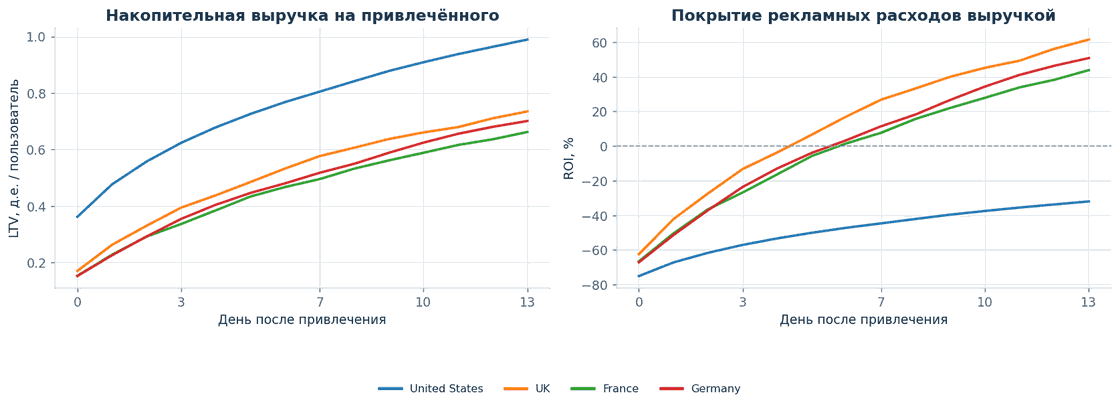

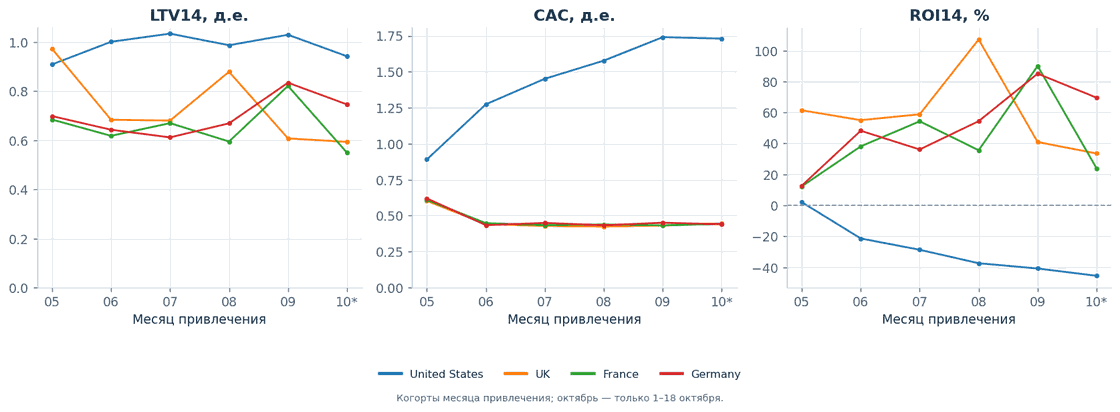

In [21]:
country_metrics = summary_table(paid, 'region', 'Страна первого визита; только зрелое платное привлечение')
plot_economics_curves(paid, 'region')
plot_monthly(paid, 'region')

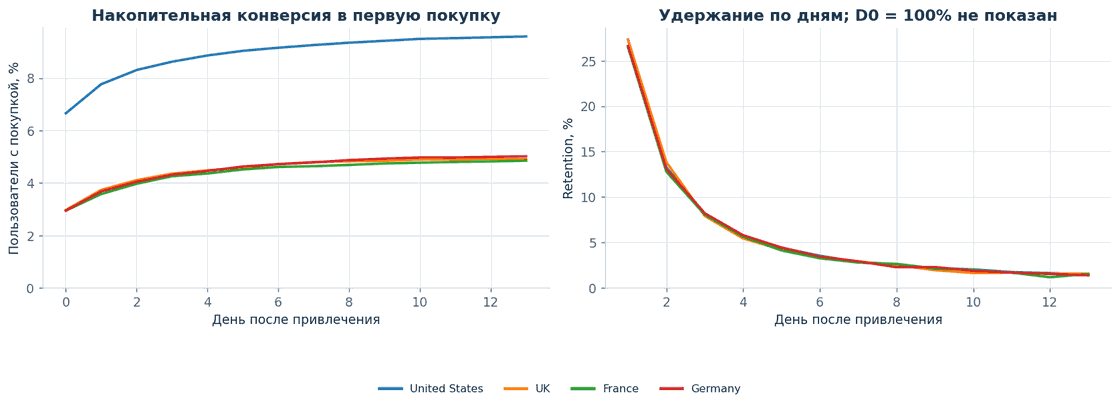

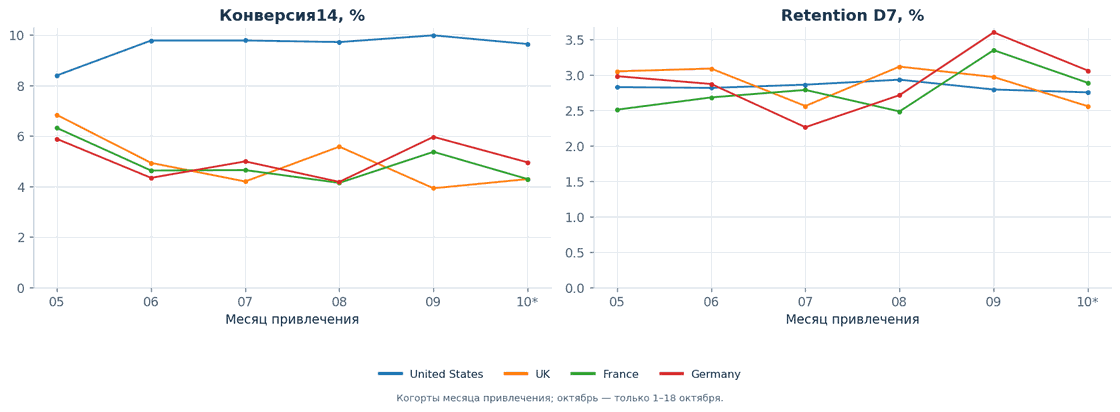

In [22]:
plot_behavior_curves(paid, 'region')
plot_monthly(paid, 'region', behavior=True)

**США** дают большую аудиторию и высокую конверсию14 — **9,58%**, но CAC **1,454** превышает LTV14 **0,989 д.е.** ROI14 равен **−31,95%**. На зрелых когортах не покрыто около **27,02 тыс. д.е.** рекламных расходов; положительные результаты других стран компенсируют только часть этой разницы.

**UK (+61,51%)**, **Germany (+50,83%)** и **France (+43,86%)** окупаются на 14-дневном горизонте при более низком CAC. Это повод проверить перераспределение, а не немедленно масштабировать расходы: результат может измениться при росте объёма. Страновые различия нельзя отделить от канального состава одним сравнением средних.

### 6.3. Рекламные каналы

,Пользователей,CAC,LTV14,ROI14,Конверсия14,Retention D7
channel,,,,,,
TipTop,"18,367",2.752,1.459,-47.0%,9.3%,4.2%
FaceBoom,"27,349",1.113,0.820,-26.4%,11.9%,1.9%
WahooNetBanner,"8,029",0.602,0.902,+49.9%,5.2%,3.3%
AdNonSense,"3,687",1.008,0.837,-16.9%,10.8%,2.6%
OppleCreativeMedia,"8,078",0.250,0.407,+63.0%,2.6%,2.6%
RocketSuperAds,"4,225",0.418,0.914,+118.5%,7.3%,4.0%
LeapBob,"8,047",0.210,0.464,+120.9%,2.9%,2.4%
lambdaMediaAds,"2,049",0.727,1.733,+138.4%,10.4%,4.8%
MediaTornado,"4,148",0.219,0.533,+143.3%,3.4%,2.4%


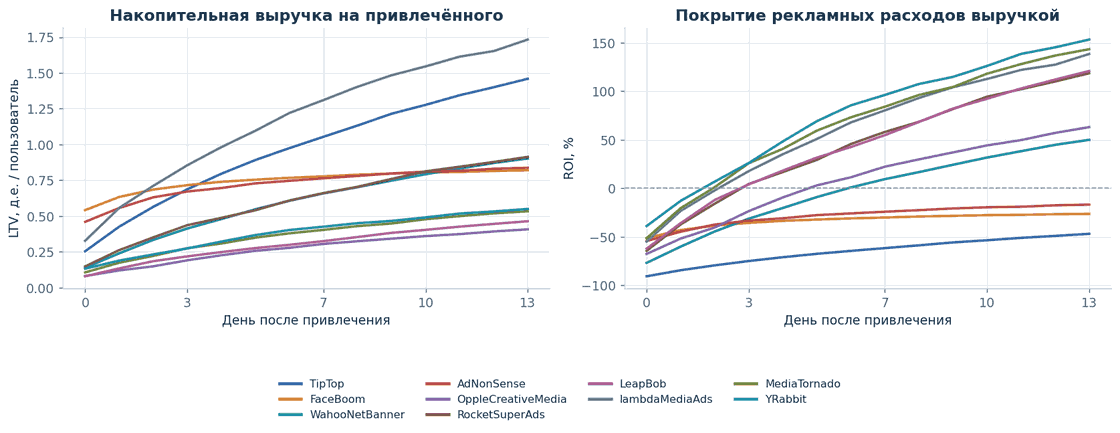

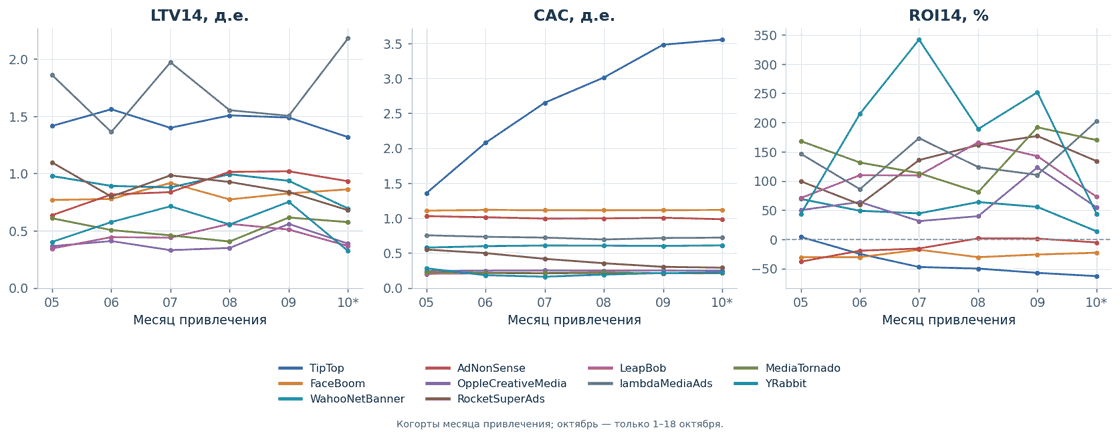

In [23]:
channel_metrics = summary_table(paid, 'channel', 'Каждый платный канал: одинаковый горизонт дней 0–13')
plot_economics_curves(paid, 'channel')
plot_monthly(paid, 'channel')

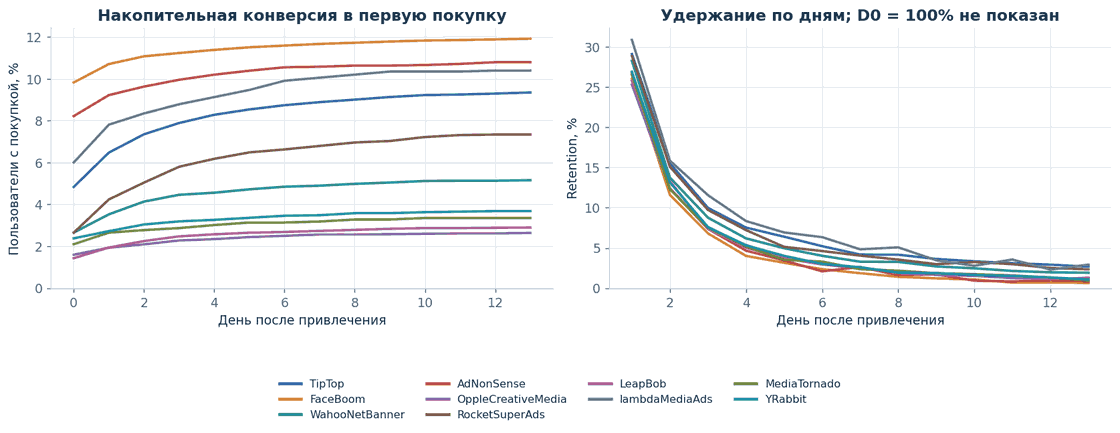

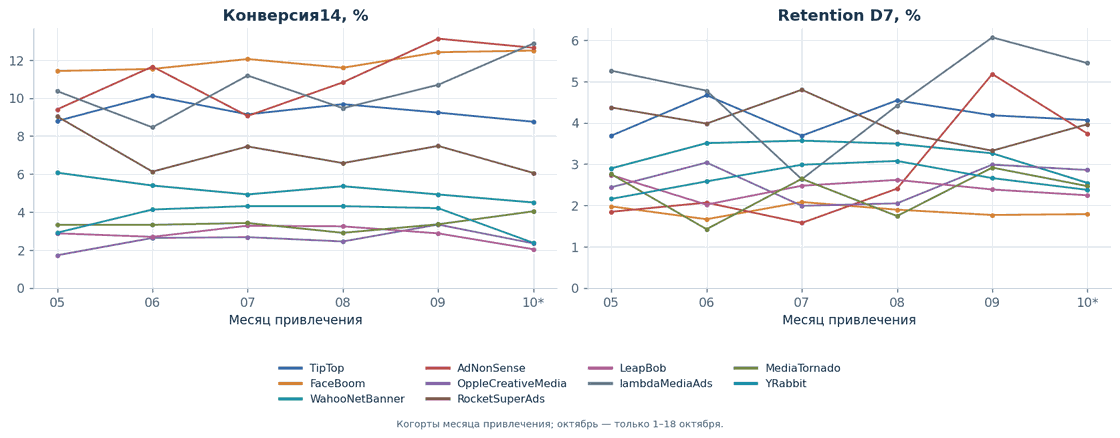

In [24]:
plot_behavior_curves(paid, 'channel')
plot_monthly(paid, 'channel', behavior=True)

**TipTop** — главный источник непокрытых рекламных расходов: CAC **2,752** при LTV14 **1,459**, ROI14 **−46,97%**, разница выручки и привлечения **−23,74 тыс. д.е.** С мая по сентябрь CAC канала вырос с **1,357 до 3,480 (+156,4%)**, а LTV14 — лишь с **1,415 до 1,488 (+5,2%)**. Наращивание стоимости не сопровождается сопоставимым улучшением монетизации.

**FaceBoom** имеет высокую конверсию14 (**11,92%**), но ROI14 **−26,37%**. Нужна проверка повторной активности и покупок: одна первая конверсия не описывает всю экономику.

**AdNonSense** также отрицателен в целом (**−16,92%**), хотя август и сентябрь близки к порогу либо немного выше него. Семь остальных каналов показывают положительную окупаемость зрелых когорт на две недели. У части из них небольшие бюджеты и аудитории; высокая средняя отдача не гарантирует того же результата при масштабировании.

In [25]:
# Первая дата окупаемости внутри имеющегося 14-дневного горизонта.
ltv_channels, _, _ = get_curves(paid, 'channel')
payback = channel_metrics[['users', 'CAC', 'LTV14', 'ROI14', 'gap14']].copy()
payback['Первый день покрытия'] = [
    str(int(np.flatnonzero((ltv_channels.loc[ch] / channel_metrics.loc[ch, 'CAC']).to_numpy() >= 1)[0]))
    if (ltv_channels.loc[ch] >= channel_metrics.loc[ch, 'CAC']).any() else 'Не достигнут за 0–13'
    for ch in payback.index]
table(payback.sort_values('gap14').rename(columns={'users': 'Пользователей', 'gap14': 'Выручка14 − расходы'}),
      {'Пользователей': '{:,.0f}', 'CAC': '{:.3f}', 'LTV14': '{:.3f}', 'ROI14': '{:+.1%}',
       'Выручка14 − расходы': '{:+,.2f}'}, 'Вклад каналов и наблюдаемая окупаемость; день 0 — дата привлечения')

,Пользователей,CAC,LTV14,ROI14,Выручка14 − расходы,Первый день покрытия
channel,,,,,,
TipTop,"18,367",2.752,1.459,-47.0%,"-23,738.06",Не достигнут за 0–13
FaceBoom,"27,349",1.113,0.820,-26.4%,"-8,031.36",Не достигнут за 0–13
AdNonSense,"3,687",1.008,0.837,-16.9%,-628.62,Не достигнут за 0–13
OppleCreativeMedia,"8,078",0.250,0.407,+63.0%,"+1,271.64",5
MediaTornado,"4,148",0.219,0.533,+143.3%,"+1,303.52",2
YRabbit,"4,077",0.217,0.550,+153.3%,"+1,356.05",2
LeapBob,"8,047",0.210,0.464,+120.9%,"+2,042.87",3
lambdaMediaAds,"2,049",0.727,1.733,+138.4%,"+2,061.96",3
RocketSuperAds,"4,225",0.418,0.914,+118.5%,"+2,093.43",3


### 6.4. Повторные покупки и состав трафика

Проверим два возможных объяснения: качество повторной монетизации FaceBoom и смешение стран/устройств с рекламными каналами. Эти разрезы описательные и не устанавливают причинное воздействие канала.

,Плательщиков14,Конверсия14,"ARPPU14, д.е.",Заказов / плательщика,D7: все,D7: плательщики14
channel,,,,,,
TipTop,"1,717",9.3%,15.61,2.93,4.2%,29.4%
FaceBoom,"3,259",11.9%,6.88,1.26,1.9%,3.5%
WahooNetBanner,414,5.2%,17.50,3.24,3.3%,38.4%
AdNonSense,398,10.8%,7.76,1.42,2.6%,6.8%
OppleCreativeMedia,213,2.6%,15.45,2.87,2.6%,34.3%
RocketSuperAds,310,7.3%,12.45,2.32,4.0%,33.2%
LeapBob,233,2.9%,16.02,3.03,2.4%,29.2%
lambdaMediaAds,213,10.4%,16.67,3.02,4.8%,33.8%
MediaTornado,139,3.4%,15.92,2.96,2.4%,25.9%


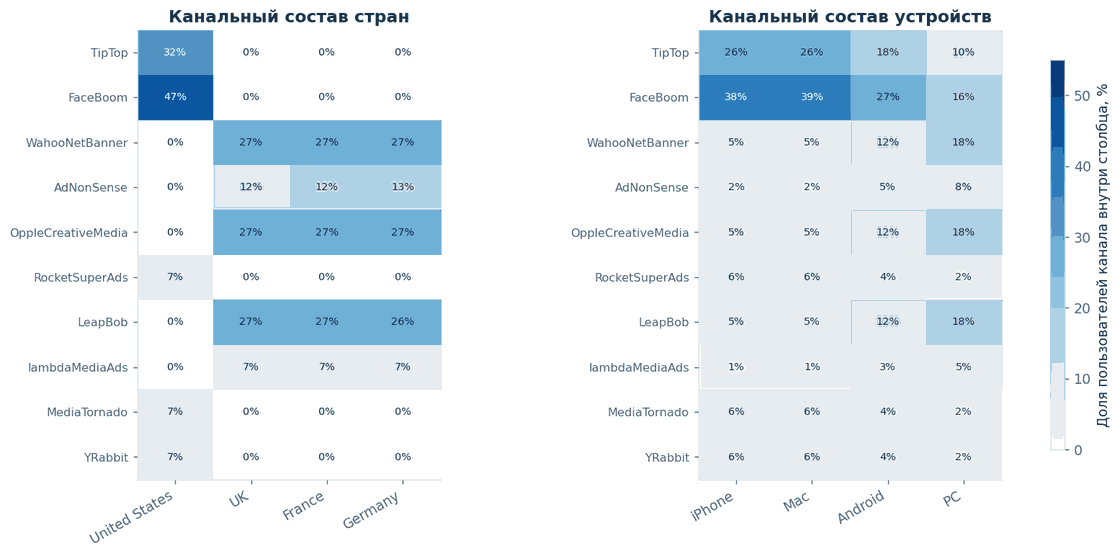

,Пользователей,CAC,LTV14,ROI14,Конверсия14,Retention D7
mix,,,,,,
TipTop + FaceBoom,"45,716",1.772,1.077,-39.2%,10.9%,2.8%
Остальные каналы США,"12,450",0.286,0.668,+133.5%,4.8%,3.0%


,users,payers14,spend,revenue14,orders14,conversion14,retention7,retention13,CAC,LTV14,ROI14,gap14,ARPPU14,orders_per_payer14
mix,,,,,,,,,,,,,,
TipTop + FaceBoom,45716,4976,"80,992.100","49,222.680",9132,0.109,0.028,0.015,1.772,1.077,-0.392,"-31,769.420",9.892,1.835
Остальные каналы США,12450,599,"3,560.555","8,313.550",1545,0.048,0.030,0.015,0.286,0.668,1.335,"4,752.995",13.879,2.579


In [26]:
diagnostics = channel_metrics[['payers14', 'conversion14', 'ARPPU14', 'orders_per_payer14', 'retention7']].copy()
paying14 = paid.loc[paid['payer14']]
diagnostics['payer_retention7'] = paying14.groupby('channel')['ret_d7'].mean()
table(diagnostics.reindex(CHANNEL_ORDER).rename(columns={
    'payers14': 'Плательщиков14', 'conversion14': 'Конверсия14', 'ARPPU14': 'ARPPU14, д.е.',
    'orders_per_payer14': 'Заказов / плательщика', 'retention7': 'D7: все',
    'payer_retention7': 'D7: плательщики14'}),
    {'Плательщиков14': '{:,.0f}', 'Конверсия14': '{:.1%}', 'ARPPU14, д.е.': '{:.2f}',
     'Заказов / плательщика': '{:.2f}', 'D7: все': '{:.1%}', 'D7: плательщики14': '{:.1%}'},
    'Плательщик14 определён по покупке за весь горизонт; это описание подгруппы, не причинное сравнение')

fig, axes = plt.subplots(1, 2, figsize=(13, 6.4))
for ax, dim, title in [(axes[0], 'region', 'Канальный состав стран'),
                         (axes[1], 'device', 'Канальный состав устройств')]:
    mix = pd.crosstab(paid['channel'], paid[dim], normalize='columns').reindex(
        index=CHANNEL_ORDER, columns=DIMENSION_ORDERS[dim], fill_value=0) * 100
    image = ax.imshow(mix.to_numpy(), aspect='auto', cmap='Blues', vmin=0, vmax=55)
    ax.set_xticks(range(len(mix.columns)), mix.columns, rotation=30, ha='right')
    ax.set_yticks(range(len(mix.index)), mix.index, fontsize=9)
    ax.set_title(title)
    ax.grid(visible=False)
    for y in range(len(mix.index)):
        for x in range(len(mix.columns)):
            value = mix.iloc[y, x]
            ax.text(x, y, f'{value:.0f}%', ha='center', va='center', fontsize=8,
                    color='white' if value > 30 else COLORS['ink'])
fig.subplots_adjust(left=0.15, right=0.86, bottom=0.15, wspace=0.85, top=0.9)
color_axis = fig.add_axes([0.90, 0.20, 0.012, 0.65])
fig.colorbar(image, cax=color_axis, label='Доля пользователей канала внутри столбца, %')
plt.show()

us = paid.loc[paid['region'].eq('United States')].copy()
us['mix'] = np.where(us['channel'].isin(['TipTop', 'FaceBoom']), 'TipTop + FaceBoom', 'Остальные каналы США')
summary_table(us, 'mix', 'Проверка состава американского трафика')

У **FaceBoom** всего **1,26 заказа на плательщика** за две недели и ARPPU14 **6,88 д.е.** У TipTop — **2,93 заказа** и **15,61 д.е.** соответственно. Среди пользователей, оплативших за 14 дней, на D7 возвращаются **3,50%** в FaceBoom и **29,35%** в TipTop. Это согласуется со слабой повторной активностью FaceBoom, но не объясняет её причину: нужны данные о кампаниях, ожиданиях аудитории и продуктовых сценариях.

TipTop и FaceBoom целиком относятся к **США** в first-touch-профилях. Остальные каналы США в сумме имеют положительный ROI14. Следовательно, отрицательный страновой результат нельзя автоматически считать свойством американских пользователей. Похожим образом различается канальный состав устройств; гипотезы о технических проблемах конкретной ОС из этих данных не следуют.

<a id="section-7"></a>
## 7. Причины, рекомендации и ограничения

### 7.1. Устойчивость к определению двух недель

Основные графики используют календарные возраста 0–13. Дополнительно проверим точное окно **336 часов от первого визита**. Для него зрелость требует `first_touch + 14 суток ≤ 1 ноября`; последняя допустимая дата привлечения — 17 октября. Это проверка чувствительности определения горизонта, а не замена основной методики.

In [27]:
elapsed_base = profiles.loc[profiles['channel'].ne('organic') &
                             (profiles['first_touch'] + pd.Timedelta(days=14) <= data_end)].copy()
elapsed_orders = orders.merge(elapsed_base[['user_id', 'first_touch']], on='user_id', validate='many_to_one')
elapsed_orders = elapsed_orders.loc[
    elapsed_orders['event_time'].ge(elapsed_orders['first_touch']) &
    elapsed_orders['event_time'].lt(elapsed_orders['first_touch'] + pd.Timedelta(days=14))]
elapsed_spend = elapsed_base['cac'].sum()
elapsed_revenue = elapsed_orders['revenue'].sum()
sensitivity = pd.DataFrame({
    'Пользователей': [len(paid), len(elapsed_base)],
    'CAC': [total['CAC'], elapsed_spend / len(elapsed_base)],
    'LTV14': [total['LTV14'], elapsed_revenue / len(elapsed_base)],
    'ROI14': [total['ROI14'], elapsed_revenue / elapsed_spend - 1],
}, index=['14 календарных дат: 0–13', '14 × 24 часа от первого визита'])
table(sensitivity, {'Пользователей': '{:,.0f}', 'CAC': '{:.3f}', 'LTV14': '{:.3f}', 'ROI14': '{:+.2%}'},
      'Основной вывод об отсутствии двухнедельной окупаемости не зависит от определения старта')
assert (sensitivity['ROI14'] < 0).all()

,Пользователей,CAC,LTV14,ROI14
14 календарных дат: 0–13,"88,056",1.116,0.891,-20.20%
14 × 24 часа от первого визита,"87,465",1.115,0.901,-19.18%


При обеих трактовках выручка за две недели не покрывает привлечение. Точное значение отличается из-за границ наблюдения и дополнительных часов в индивидуальном окне, поэтому смешивать эти определения в одной кривой нельзя.

### 7.2. Что объясняет недостаточную окупаемость

1. **Концентрация бюджета.** TipTop и FaceBoom получают 82,65% всех расходов, хотя на зрелых когортах оба не выполняют требование двух недель. Их отрицательный вклад превышает положительный вклад остальных источников.
2. **Удорожание TipTop.** CAC растёт существенно быстрее ранней выручки. Это наиболее выраженное изменение, связанное с ухудшением общей экономики.
3. **Слабая повторная монетизация FaceBoom.** Высокая конверсия в покупку сочетается с малым числом заказов и низким удержанием плательщиков. Оптимизация только первой покупки могла бы скрыть эту проблему.
4. **Смешение факторов.** Отрицательные агрегаты США, iPhone и Mac зависят от состава привлечения. Самостоятельное причинное влияние страны или устройства не установлено.

### 7.3. Действия для отдела маркетинга

| Приоритет | Действие | Как проверить результат |
|:--|:--|:--|
| 1 | Ограничить дальнейшее масштабирование TipTop; разобрать рост цены по кампаниям, аудиториям и креативам. | CAC и LTV14 новых зрелых когорт, их ROI14, объём привлечения. |
| 2 | Разобрать FaceBoom: соответствие рекламы продукту, повторные визиты и повторные покупки. | Конверсия14 вместе с ARPPU14, заказами на плательщика и удержанием. |
| 3 | Проверить AdNonSense по отдельным месяцам и кампаниям: общий результат отрицателен, последние зрелые месяцы ближе к порогу. | Динамика ROI14 при сопоставимых аудиториях и зрелости. |
| 4 | Небольшими тестами перераспределять бюджет в положительные источники, включая WahooNetBanner, RocketSuperAds и lambdaMediaAds; проверять также небольшие дешёвые каналы. | Предельная стоимость добавленного трафика и окупаемость после увеличения масштаба, а не только историческое среднее. |
| 5 | Вести регулярный отчёт по зрелым 14-дневным когортам и составу каналов внутри стран/устройств. | Единые знаменатели, сохранение суммы расходов и отсутствие молодых когорт в полных горизонтах. |

При неизменной монетизации теоретический предел CAC для покрытия рекламы выручкой равен LTV14: около **1,459 д.е. для TipTop**, **0,820 для FaceBoom**, **0,837 для AdNonSense**. Это ориентиры по наблюдаемой выручке, а не готовые ставки закупки. После учёта маржи, операционных расходов и неопределённости допустимая стоимость должна быть ниже.

### 7.4. Границы решения

Данные показывают **недостаточную окупаемость рекламы на заданном горизонте**, но не полный финансовый результат приложения. Неизвестны себестоимость, маржинальность, рекламные настройки, комиссии и операционные расходы. First touch и равномерное распределение бюджета внутри дня/канала — выбранные модели атрибуции; они не отражают всю цепочку контактов.

Выводы о каналах и поведении описательные. Рост стоимости, низкая повторная активность и состав трафика подтверждены метриками; конкретные причины вроде изменения аукциона, качества креативов или технических ошибок требуют дальнейшей проверки. Исторический ROI небольшого источника не гарантирует той же отдачи при большом бюджете.